# explore_prepared_v3 — ปิดงานที่เหลือจาก audit + EDA คอลัมน์ที่ audit เพิ่มเข้ามา

`explore_prepared_v2` ทำ EDA ตอน `target_table` ยังเป็น **44×35** · หลัง audit ไฟล์เป็น **44×44**
คอลัมน์ใหม่ 9 ตัวจึงยังไม่เคยถูกสำรวจ และตัวเลข EDA บางตัวใน v2 คำนวณจากค่าที่ถูกแก้ไปแล้ว

โน้ตบุ๊กนี้ทำ 4 อย่าง:

| § | ทำอะไร | ทำไม |
|---|---|---|
| 1 | **ด่านตรวจ audit ทั้ง 20 ข้อ จากไฟล์บนดิสก์** | รายงาน audit บอกว่าแก้แล้ว 17/20 — ตรวจซ้ำจากไฟล์จริงโดยไม่เชื่อโน้ตบุ๊กต้นทาง ถ้ามีการรัน pipeline ใหม่แล้วของหาย จะรู้ทันที |
| 2-4 | **ปิดข้อ V, L และประเมินผลกระทบของ F, I, G** ด้วยหลักฐานภายในชุดข้อมูล | audit บอกว่า 4 ข้อนี้ "ต้องเห็นเปเปอร์ต้นฉบับ" — แต่ส่วนที่ตัดสินได้จากข้อมูลเองยังไม่เคยคำนวณ ทำแล้วจะเหลือรอเปเปอร์น้อยลง |
| 5-6 | **EDA คอลัมน์ใหม่ + diff กับตัวเลขที่ v2 รายงานไว้** | ตัวเลขใน v2 และในเอกสารบางจุดคำนวณจากข้อมูลก่อนแก้ |
| 7 | **ทะเบียนสิ่งที่เหลือ** export เป็น CSV | ให้รอบหน้าหยิบไปทำต่อได้โดยไม่ต้องอ่านรายงาน 120 KB ซ้ำ |

> โน้ตบุ๊กนี้ **อ่านอย่างเดียว ไม่เขียนทับ `prepared_v2/`** — ถ้าผลที่ได้บอกให้แก้ข้อมูล
> ต้องกลับไปแก้ที่ `recheck_comlumn_preapare` แล้วรัน pipeline ใหม่ (กติกาเดิมจาก audit: แก้ที่ต้นทางเท่านั้น)
> สิ่งเดียวที่เขียนคือทะเบียนสถานะใน `processed/audit/`

In [1]:
from math import comb
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

ROOT = Path.cwd() if (Path.cwd() / "processed" / "prepared_v2").exists() else Path.cwd().parent
V2 = ROOT / "processed" / "prepared_v2"

tt = pd.read_csv(V2 / "target_table.csv")
proc = pd.read_csv(V2 / "process.csv")
prop = pd.read_csv(V2 / "properties.csv")
layers = pd.read_csv(V2 / "layers.csv")
SHAPE = tt.shape                                   # เก็บก่อนเติมคอลัมน์ช่วยงาน
tt["paper"] = tt["device_id"].str.rsplit("_Sample", n=1).str[0]

# สไตล์เดียวกับ explore_prepared_v2 / eda_htl_modification
_have = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((f for f in ["Leelawadee UI", "Sarabun", "Thonburi", "Tahoma", "Ayuthaya", "DejaVu Sans"] if f in _have),
            "DejaVu Sans")
C1, C2, C3, C4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID, BASE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "font.family": [FONT, "DejaVu Sans"], "axes.unicode_minus": False,
    "figure.dpi": 110, "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": BASE, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlecolor": INK, "axes.titlesize": 11, "font.size": 9.5})


def spearman(x, y):
    """rho, n — rank correlation เขียนเอง (ให้ผลเท่ากับ v2/eda_htl ที่ไม่ได้ใช้ scipy)"""
    m = pd.notna(x) & pd.notna(y)
    if m.sum() < 3:
        return np.nan, int(m.sum())
    return float(np.corrcoef(pd.Series(x)[m].rank(), pd.Series(y)[m].rank())[0, 1]), int(m.sum())


def sign_test(vals):
    """p สองด้านแบบ exact binomial (H0: P(+) = 0.5) -> (p, k_pos, n)"""
    v = [x for x in vals if pd.notna(x) and x != 0]
    n, k = len(v), sum(1 for x in v if x > 0)
    if n == 0:
        return np.nan, 0, 0
    pmf = [comb(n, i) * 0.5 ** n for i in range(n + 1)]
    return min(1.0, sum(q for q in pmf if q <= pmf[k] + 1e-12)), k, n


def short(p, n=24):
    return p if len(p) <= n else p[:n - 1] + "…"


# นิยาม treated/CONTRAST ให้ตรงกับ eda_htl_modification เป๊ะ ๆ (ใช้ตอนทดสอบความไวข้อ V)
_l3 = (layers[layers.layer_id == 3].groupby("device_id")["material"]
       .apply(lambda s: " + ".join(sorted(s.dropna().unique()))).replace("", np.nan))
tt["htl_mod_material"] = tt["device_id"].map(_l3)
tt["treated"] = tt["htl_mod_kind"].notna()
_v = tt.groupby("paper")["treated"].nunique()
CONTRAST = sorted(_v[_v == 2].index)

print(f"target_table {SHAPE} (บนดิสก์) | process {proc.shape} | properties {prop.shape}")
print(f"papers {tt.paper.nunique()} | contrast papers {len(CONTRAST)} | treated {int(tt.treated.sum())}")
print("เติมคอลัมน์ช่วยงานในหน่วยความจำ: paper, htl_mod_material, treated (ไม่เขียนลงไฟล์)")

target_table (44, 44) (บนดิสก์) | process (702, 72) | properties (564, 16)
papers 15 | contrast papers 11 | treated 29
เติมคอลัมน์ช่วยงานในหน่วยความจำ: paper, htl_mod_material, treated (ไม่เขียนลงไฟล์)


## 1. ด่านตรวจ audit ทั้ง 20 ข้อ — ตรวจจากไฟล์บนดิสก์

หลักการเดียวกับที่ audit ใช้: **ตรวจผลลัพธ์แบบกล่องดำ ไม่เชื่อโค้ดต้นทาง**
ทุกข้อเขียนเป็นเงื่อนไขที่ต้องเป็นจริง ถ้าไม่จริง = การแก้หายไประหว่างรัน pipeline ใหม่

`PASS` = แก้แล้วและยังอยู่ · `OPEN` = ยังค้าง (ตั้งใจ) · `FAIL` = เคยแก้แล้วแต่หายไป → ต้องหยุดแล้วสืบ

In [2]:
# ตัวเลขยืนยันแล้วของชุด 44 device (2026-08-31) -- ใช้เป็นพื้น ไม่ใช่คำตอบตายตัว
#   คอลัมน์พวกนี้ "โตได้" เมื่อเพิ่มเปเปอร์ แต่ถ้า *หด* แปลว่าการแก้จาก audit หลุดหาย
BASELINE = {"vbm_offset": 3, "sheet_resistance_htl": 2, "rs": 20, "defect_density_reported": 2,
            "trap_density_electron": 3, "value_note_diff": 11, "rrec_suspect": 2,
            "mobility": 9, "mobility_htl": 3}
grew = []


def at_least(key, actual):
    """ผ่านถ้า actual ไม่น้อยกว่า baseline · บันทึกไว้ถ้าโตขึ้น จะได้เห็นว่าข้อมูลใหม่เพิ่มอะไร"""
    base = BASELINE[key]
    if actual > base:
        grew.append({"รายการ": key, "baseline": base, "ปัจจุบัน": actual, "เพิ่ม": actual - base})
    return actual >= base


checks = []


def chk(item, name, ok, detail, note=""):
    """ok: True/False = ผ่าน/ไม่ผ่าน · None = ค้างโดยตั้งใจ (numpy bool ก็รับได้)"""
    state = "OPEN" if ok is None else ("PASS" if bool(ok) else "FAIL")
    checks.append(dict(ข้อ=item, รายการ=name, สถานะ=state, หลักฐาน=detail, หมายเหตุ=note))


# --- A, B: ค่าที่ถูกกรอกในช่อง Descriptions ถูกกู้กลับมาแล้ว ---
rec = proc[proc.param_recovered == True]
_solr = tt.loc[tt.device_id == "10_1002_solr_202400534_Sample2", "psk_spin_rpm"].squeeze()
_ac = tt[tt.paper == "10_1021_acsami_5c15868"]
chk("A", "psk_spin_rpm ของ solr_202400534_Sample2", _solr == 5000,
    f"psk_spin_rpm = {_solr:.0f} (ที่ผิดคือ 1000)")
chk("B", "ค่าที่หายของ acsami_5c15868_Sample1", _ac.psk_spin_rpm.notna().all() and _ac.htl_anneal_C.notna().all(),
    f"กู้ได้ {len(rec)} แถวใน process · Sample1 มี rpm/anneal ครบ", "เท่ากับ Sample2/3 ทั้ง paper")

# --- C, D: เครื่องหมาย VBM + แยกชื่อที่ชนกัน ---
vbm = prop[prop.base_property == "VBM"]
off = prop[prop.base_property == "VBM offset from EF"]
chk("C", "เครื่องหมาย VBM (อ้างอิงสุญญากาศต้องเป็นลบ)", bool((vbm.value_parsed < 0).all()),
    f"VBM {len(vbm)} แถว ค่าลบทั้งหมด · ต่ำสุด {vbm.value_parsed.min():.2f} สูงสุด {vbm.value_parsed.max():.2f} eV")
chk("D", "แยก VBM (สุญญากาศ) ออกจาก E_F−E_VBM",
    at_least("vbm_offset", len(off)) and bool((off.value_parsed > 0).all()),
    f"'VBM offset from EF' {len(off)} แถว (พื้น {BASELINE['vbm_offset']}) ค่าบวกทั้งหมด")

# --- E: sheet resistance แยกออกจาก rs ---
chk("E", "Rs ของ smll เป็นความต้านทานแผ่น",
    at_least("sheet_resistance_htl", int(tt.sheet_resistance_htl.notna().sum()))
    and at_least("rs", int(tt.rs.notna().sum())),
    f"rs {int(tt.rs.notna().sum())} device (พื้น {BASELINE['rs']}) · "
    f"sheet_resistance_htl {int(tt.sheet_resistance_htl.notna().sum())} device")

# --- F, G, I: ธงที่แปลงข้อความเตือนเป็นตัวเลขในไฟล์ ---
chk("F", "Defect density เก็บแยกพร้อมเหตุผล",
    at_least("defect_density_reported", int(tt.defect_density_reported.notna().sum())),
    f"defect_density_reported {int(tt.defect_density_reported.notna().sum())} device "
    f"(พื้น {BASELINE['defect_density_reported']})", "คำตอบสุดท้ายยังรอ Fig. 2c")
chk("G", "ธงสเกลของ trap density", "scale_suspect" in set(tt.trap_scale_flag.dropna()),
    f"trap_scale_flag: {tt.trap_scale_flag.value_counts().to_dict()}")
_sus = int((tt.rrec_scale_flag == "scale_suspect").sum())
_flag_by_paper = tt[tt.rrec.notna()].groupby("paper").rrec_scale_flag.nunique()
chk("I", "ธงสเกลของ Rrec (ต้องเท่ากันทั้งเปเปอร์)",
    at_least("rrec_suspect", _sus) and bool(_flag_by_paper.eq(1).all()),
    f"scale_suspect {_sus} device (พื้น {BASELINE['rrec_suspect']}) · "
    f"ธงสม่ำเสมอทุกเปเปอร์ {int(_flag_by_paper.eq(1).sum())}/{len(_flag_by_paper)}",
    "นิยามยังรอ Table S2")

# --- H: trap ฝั่งโฮล/อิเล็กตรอนแยกกัน ---
chk("H", "trap_density ไม่เฉลี่ยข้ามชนิดพาหะแล้ว",
    at_least("trap_density_electron", int(tt.trap_density_electron.notna().sum())),
    f"trap_density_electron {int(tt.trap_density_electron.notna().sum())} device "
    f"(พื้น {BASELINE['trap_density_electron']})")

# --- J: bandgap ระบุชั้น ---
bg = prop[prop.base_property.astype(str).str.contains("band ?gap", case=False, na=False)]
hi = bg[bg.value_parsed > 2.5]
chk("J", "Bandgap > 2.5 eV ต้องระบุชั้น", bool((hi.layer == "HTL").all()) and len(hi) > 0,
    f"แถบพลังงาน > 2.5 eV {len(hi)} แถว ระบุ layer = HTL ครบ")

# --- M: ชื่อคอลัมน์ + ทุกความต่างต้องมีคำอธิบาย ---
_d = prop[prop.value_after_unit_fix.notna() & prop.value_parsed.notna()].copy()
_d["vaf"] = pd.to_numeric(_d.value_after_unit_fix, errors="coerce")
diff = _d[~np.isclose(_d.vaf, _d.value_parsed, rtol=1e-9, atol=1e-12)]
chk("M", "value_after_unit_fix + ทุกความต่างมี value_note",
    "value_after_unit_fix" in prop.columns and "value_corrected" not in prop.columns
    and diff.value_note.notna().all(),
    f"ต่างกัน {len(diff)} แถว · มี value_note ครบ {int(diff.value_note.notna().sum())}/{len(diff)}")

# --- N: psk_spin_rpm กับ psk_spin_last_s ต้องมาจากขั้นเดียวกัน ---
_p = proc[(proc.source_sheet == "Process") & proc.process_type.notna() & (proc.layer_id == 4)
          & (proc.process_type == "Spin coating")]
_last = (_p.sort_values("step_order").groupby("device_id").tail(1)
         .set_index("device_id")["Spin coating__RPM"])
_agree = tt.set_index("device_id").psk_spin_rpm.dropna().eq(
    _last.reindex(tt.set_index("device_id").psk_spin_rpm.dropna().index)).mean()
chk("N", "psk_spin_rpm มาจากขั้นสุดท้ายจริง (ไม่ใช่ max)", _agree == 1.0,
    f"ตรงกับค่า RPM ของ step_order สูงสุด {_agree:.0%} ของ device ที่มีค่า")

# --- O: JV มาจากชุด + ทิศทางเดียวกัน ---
err = (tt.pce - tt.voc * tt.jsc * tt.ff / 100).abs()
over = tt.loc[err > 0.2, "device_id"].tolist()
chk("O", "JV ไม่ปนชุด/ไม่ปนทิศทางสแกน", "jv_scan" in tt.columns and set(over) <= {"10_31635_ccschem_025_202505977_Sample1", "10_1016_j_heliyon_2024_e25352_Sample3"},
    f"มี jv_scan · ค่าคลาดสูงสุด {err.max():.3f} · เกิน 0.2 เหลือ {len(over)} device",
    "ที่เหลือ = ข้อ V (เปเปอร์เอง) + heliyon (ปัดเศษ)")

# --- P, Q: ด่านตรวจย้ายมาก่อน export (ตรวจว่าไม่มีแถวไหนหลุด) ---
chk("P/Q", "ด่านตรวจครอบทุกแถวที่สองคอลัมน์ต่างกัน",
    bool(diff.value_note.notna().all()) and at_least("value_note_diff", len(diff)),
    f"{len(diff)} แถว (พื้น {BASELINE['value_note_diff']}) มีคำอธิบายครบทุกแถว",
    "เดิมเงื่อนไขยกเว้น FF พอดี")

# --- R, S: split_param ไม่ทิ้งข้อมูลเงียบ ---
loss = proc[proc.parameter.notna() & proc.unit.isna()]
chk("R/S", "split_param ไม่ทิ้งข้อมูลเงียบ", "param_note" in proc.columns and len(loss) == 0,
    f"แถวที่มี parameter แต่ไม่มี unit = {len(loss)} · param_note ติดธง {int(proc.param_note.notna().sum())} แถว")

# --- U: ตัวตรวจหน่วยอิงช่วงค่าทางฟิสิกส์ (ตรวจผลลัพธ์ ไม่ใช่ตรวจโค้ด) ---
RANGE = {"VBM": (-7, -3), "Fermi level": (-7, -3), "VBM offset from EF": (0, 2)}
bad = [(r.device_id, r.base_property, r.value_parsed)
       for r in prop.itertuples() if r.base_property in RANGE
       and pd.notna(r.value_parsed) and not (RANGE[r.base_property][0] <= r.value_parsed <= RANGE[r.base_property][1])]
chk("U", "ค่าอยู่ในช่วงที่เป็นไปได้ทางฟิสิกส์", len(bad) == 0,
    f"ตรวจ {len(RANGE)} ปริมาณ · หลุดช่วง {len(bad)} แถว")

# --- K: ค่า mobility ถูกอยู่แล้ว แต่ต้องบอกได้ว่าเป็นของชั้นไหน หรือติดธงว่ายังไม่รู้ ---
mob = prop[prop.base_property.astype(str).str.contains("mobil", case=False, na=False)]
mob_ok = mob.layer.notna() | mob.value_note.fillna("").str.contains("audit ข้อ K")
chk("K", "mobility ระบุชั้น หรือติดธงว่ายังไม่รู้",
    bool(mob_ok.all()) and at_least("mobility", len(mob))
    and at_least("mobility_htl", int((mob.layer == "HTL").sum())),
    f"{len(mob)} แถว (พื้น {BASELINE['mobility']}) · layer=HTL {int((mob.layer == 'HTL').sum())} "
    f"(หลักฐาน stack ใน remarks) · ติดธงไว้ {int(mob.layer.isna().sum())}",
    "ค่าไม่ต้องแก้ — audit ตรวจไขว้ sigma = n*e*mu แล้วตรง")

# --- L: ชื่อคอลัมน์ต้องบอกตัวหาร และตัวหลักต้องไม่มีเคสที่เป็นไปไม่ได้ ---
frac = tt.antisolvent_drop_frac_of_total.dropna()
chk("L", "จุดอ้างอิงจังหวะหยด — ชื่อไม่กำกวม + ตัวหลักผ่านฟิสิกส์",
    "antisolvent_drop_frac" not in tt.columns and bool(((frac > 0) & (frac < 0.999)).all()),
    f"of_total {len(frac)} dev ช่วง {frac.min():.3f}–{frac.max():.3f} · "
    f"of_last แตะ 1.00 {int((tt.antisolvent_drop_frac_of_last >= 0.999).sum())} device",
    "ยังต้องยืนยันด้วยเปเปอร์ก่อนเขียน methods — ดู §2")

# --- V: ยังค้าง (ตั้งใจ) ---
chk("V", "ตัวเลข JV ของ ccschem_Sample1 ไม่ลงตัว 0.50", None,
    f"ค่าคลาด {err.max():.3f} — เป็นความไม่สอดคล้องในเปเปอร์เอง", "ทดสอบความไวแล้ว — ดู §3")

gate = pd.DataFrame(checks)
display(gate.set_index("ข้อ"))

n_fail = int((gate.สถานะ == "FAIL").sum())
print(f"PASS {int((gate.สถานะ == 'PASS').sum())} · OPEN {int((gate.สถานะ == 'OPEN').sum())} · FAIL {n_fail}")
assert n_fail == 0, f"การแก้จาก audit หายไป {n_fail} ข้อ — หยุดก่อน อย่าเอาข้อมูลไปใช้ต่อ"
print("✓ การแก้จาก audit ทั้งหมดยังอยู่ครบในไฟล์บนดิสก์")

# จำนวน device ต้องตรงกับไฟล์ใน Raw Data -- ไม่ hardcode
_raw = ROOT / "Raw Data"
if _raw.exists():
    _n_raw = len(sorted(_raw.glob("*.xlsx")))
    assert len(tt) == _n_raw, f"target_table {len(tt)} แถว แต่ Raw Data มี {_n_raw} ไฟล์"
    print(f"✓ {len(tt)} device ตรงกับจำนวนไฟล์ใน Raw Data/")

if grew:
    print()
    print("ข้อมูลโตขึ้นจาก baseline ของชุด 44 device — ตรวจว่ามาจากเปเปอร์ใหม่จริง ไม่ใช่ค่าหลุดเข้ามา:")
    display(pd.DataFrame(grew).set_index("รายการ"))
    print("ถ้าเห็นว่าถูกต้องแล้ว ให้อัปเดตเลขใน BASELINE ด้านบนให้ตรงกับชุดใหม่")

,รายการ,สถานะ,หลักฐาน,หมายเหตุ
ข้อ,,,,
A,psk_spin_rpm ของ solr_202400534_Sample2,PASS,psk_spin_rpm = 5000 (ที่ผิดคือ 1000),
B,ค่าที่หายของ acsami_5c15868_Sample1,PASS,กู้ได้ 12 แถวใน process · Sample1 มี rpm/annea...,เท่ากับ Sample2/3 ทั้ง paper
C,เครื่องหมาย VBM (อ้างอิงสุญญากาศต้องเป็นลบ),PASS,VBM 12 แถว ค่าลบทั้งหมด · ต่ำสุด -5.72 สูงสุด ...,
D,แยก VBM (สุญญากาศ) ออกจาก E_F−E_VBM,PASS,'VBM offset from EF' 3 แถว (พื้น 3) ค่าบวกทั้งหมด,
E,Rs ของ smll เป็นความต้านทานแผ่น,PASS,rs 20 device (พื้น 20) · sheet_resistance_htl ...,
F,Defect density เก็บแยกพร้อมเหตุผล,PASS,defect_density_reported 2 device (พื้น 2),คำตอบสุดท้ายยังรอ Fig. 2c
G,ธงสเกลของ trap density,PASS,"trap_scale_flag: {'ok': 16, 'scale_suspect': 5...",
I,ธงสเกลของ Rrec (ต้องเท่ากันทั้งเปเปอร์),PASS,scale_suspect 2 device (พื้น 2) · ธงสม่ำเสมอทุ...,นิยามยังรอ Table S2
H,trap_density ไม่เฉลี่ยข้ามชนิดพาหะแล้ว,PASS,trap_density_electron 3 device (พื้น 3),


PASS 18 · OPEN 1 · FAIL 0
✓ การแก้จาก audit ทั้งหมดยังอยู่ครบในไฟล์บนดิสก์
✓ 44 device ตรงกับจำนวนไฟล์ใน Raw Data/


## 2. ข้อ L — จุดอ้างอิงจังหวะหยด: ตัดสินแล้วด้วยหลักฐานฟิสิกส์

audit จัดข้อนี้เป็น "ต้องเปิดเปเปอร์" เพราะค่าบวกตีความได้ 2 ทาง · ตอนนี้เก็บไว้ทั้งคู่
โดย**ตั้งชื่อตามตัวหาร** เพื่อไม่ให้กำกวมอีก (ชื่อเดิม `antisolvent_drop_frac` ไม่บอกว่าหารด้วยอะไร):

| คอลัมน์ | ตัวหาร | หมายความว่า |
|---|---|---|
| **`antisolvent_drop_frac_of_total`** ⭐ ตัวหลัก | `psk_spin_total_s` | "เริ่มปั่น" = เริ่มโปรแกรม spin ทั้งหมด |
| `antisolvent_drop_frac_of_last` ทางเลือก | `psk_spin_last_s` | "เริ่มปั่น" = เริ่ม spin ขั้นสุดท้าย |

**เกณฑ์ที่ใช้ตัดสินโดยไม่ต้องเปิดเปเปอร์**: antisolvent ต้องหยด**ก่อน**หยุดปั่น
ถ้าสัดส่วน = 1.00 แปลว่าหยดตอนวินาทีสุดท้ายพอดี ซึ่งเป็นไปไม่ได้ — ฟิล์มไม่มีเวลาตกผลึกใต้แรงเหวี่ยง

,n,ref,timing,spin_last,spin_total,of_total,of_last,of_total เป็นไปได้ไหม,of_last เป็นไปได้ไหม
paper,,,,,,,,,
10.1002admi.202500231,4,before_end,-10.0,35.0,45.0,0.556,0.714,ได้,ได้
10.1016j.jechem.2021.11.029,2,after_start,8.0,40.0,50.0,0.160,0.200,ได้,ได้
10.1021_acsami.5c16972,2,before_end,-5.0,40.0,50.0,0.700,0.875,ได้,ได้
10_1002_smll_202504237,2,after_start,15.0,30.0,40.0,0.375,0.500,ได้,ได้
10_1002_solr_202200422,2,after_start,25.0,30.0,40.0,0.625,0.833,ได้,ได้
10_1016_j_heliyon_2024_e25352,5,after_start,20.0,30.0,40.0,0.500,0.667,ได้,ได้
10_1016_j_solener_2025_113286,2,after_start,15.0,30.0,40.0,0.375,0.500,ได้,ได้
10_1021_acsami_4c14300,2,after_start,15.0,50.0,50.0,0.300,0.300,ได้,ได้
10_1021_acsami_5c15868,3,after_start,30.0,30.0,40.0,0.750,1.000,ได้,เป็นไปไม่ได้


of_total (ตัวหลัก) แตะ 1.00: 0 เปเปอร์
of_last  (ทางเลือก) แตะ 1.00: 1 เปเปอร์ -> ['10_1021_acsami_5c15868']


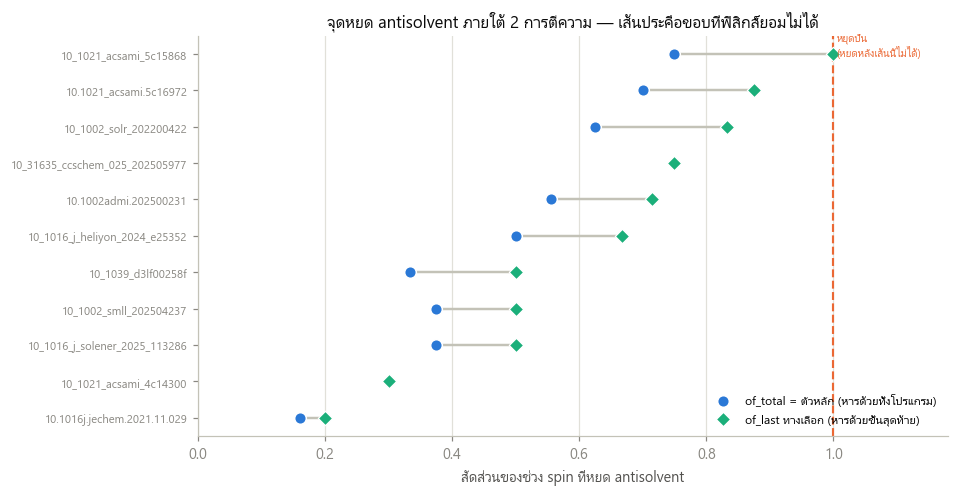

In [3]:
MAIN, ALT = "antisolvent_drop_frac_of_total", "antisolvent_drop_frac_of_last"
a = tt[tt[MAIN].notna() | tt[ALT].notna()].copy()
g = (a.groupby("paper")
     .agg(n=("device_id", "size"), ref=("antisolvent_timing_ref", "first"),
          timing=("antisolvent_timing_s", "first"), spin_last=("psk_spin_last_s", "first"),
          spin_total=("psk_spin_total_s", "first"),
          of_total=(MAIN, "first"), of_last=(ALT, "first")))
g["of_total เป็นไปได้ไหม"] = np.where(g.of_total >= 0.999, "เป็นไปไม่ได้", "ได้")
g["of_last เป็นไปได้ไหม"] = np.where(g.of_last >= 0.999, "เป็นไปไม่ได้", "ได้")
display(g.round(3))

print(f"of_total (ตัวหลัก) แตะ 1.00: {int((g.of_total >= 0.999).sum())} เปเปอร์")
print(f"of_last  (ทางเลือก) แตะ 1.00: {int((g.of_last >= 0.999).sum())} เปเปอร์ "
      f"-> {list(g.index[g.of_last >= 0.999])}")

fig, ax = plt.subplots(figsize=(8.8, 4.6))
o = g.sort_values("of_last")
y = np.arange(len(o))
ax.hlines(y, o.of_total, o.of_last, color=BASE, lw=1.6, zorder=1)
ax.scatter(o.of_total, y, s=58, color=C1, edgecolor="white", lw=1, zorder=3,
           label="of_total = ตัวหลัก (หารด้วยทั้งโปรแกรม)")
ax.scatter(o.of_last, y, s=44, color=C3, marker="D", edgecolor="white", lw=0.8, zorder=3,
           label="of_last ทางเลือก (หารด้วยขั้นสุดท้าย)")
ax.axvline(1.0, color=C2, lw=1.4, ls="--", zorder=2)
ax.text(1.005, len(o) - 0.4, "หยุดปั่น" + chr(10) + "(หยดหลังเส้นนี้ไม่ได้)", fontsize=7.2, color=C2, va="top")
ax.set_yticks(y, [short(p, 30) for p in o.index], fontsize=7.4)
ax.set_xlabel("สัดส่วนของช่วง spin ที่หยด antisolvent"); ax.set_xlim(0, 1.18)
ax.grid(axis="y", visible=False); ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("จุดหยด antisolvent ภายใต้ 2 การตีความ — เส้นประคือขอบที่ฟิสิกส์ยอมไม่ได้")
plt.tight_layout(); plt.show()

In [4]:
# หลักฐานที่สอง: การตีความไหนสัมพันธ์กับผลลัพธ์ดีกว่า (naive เท่านั้น ยังไม่คุม paper)
rows = []
for col, lab in [("antisolvent_timing_s", "timing_s (ค่าดิบ 2 จุดอ้างอิง)"),
                 ("antisolvent_drop_s", "drop_s (วินาที แกนเดียวกัน)"),
                 (MAIN, "drop_frac_of_total = ตัวหลัก"),
                 (ALT, "drop_frac_of_last (ทางเลือก)")]:
    r = dict(ตัวแปร=lab)
    for y in ["pce", "voc", "ff", "vtfl"]:
        rho, n = spearman(tt[col], tt[y])
        r[y] = f"{rho:+.3f}"
    r["n"] = int((tt[col].notna() & tt.pce.notna()).sum())
    rows.append(r)
display(pd.DataFrame(rows).set_index("ตัวแปร"))

print("สรุปข้อ L — สถานะ: สลับตัวหลักเป็น of_total แล้วใน recheck §9")
print("  1. of_last บังคับให้ acsami_5c15868 หยดตอนหยุดปั่นพอดี (1.00) ซึ่งเป็นไปไม่ได้ · of_total ไม่มีเคสแบบนี้")
print("  2. of_total สัมพันธ์กับ pce/voc สูงกว่าเล็กน้อยทุกคู่ (ทิศทางเดียวกัน ไม่ใช่หลักฐานเดี่ยว ๆ)")
print("  3. ตัวแปรนี้แปรผันภายในเปเปอร์ 0/15 -> ถูกตัดจากโมเดลหลักอยู่แล้ว การเลือกไม่กระทบผล")
print()
print("ยังเหลือ: ยืนยันด้วยเปเปอร์ acsami_5c15868 / acsami.5c16972 ก่อนเขียนลง methods")
print("         ถ้าเปเปอร์บอกว่า of_last ถูก แค่สลับคอลัมน์กลับ ไม่ต้องคำนวณใหม่")

,pce,voc,ff,vtfl,n
ตัวแปร,,,,,
timing_s (ค่าดิบ 2 จุดอ้างอิง),+0.428,+0.520,+0.248,-0.281,33
drop_s (วินาที แกนเดียวกัน),+0.457,+0.354,+0.436,-0.281,33
drop_frac_of_total = ตัวหลัก,+0.525,+0.466,+0.482,-0.068,31
drop_frac_of_last (ทางเลือก),+0.497,+0.388,+0.496,+0.079,31


สรุปข้อ L — สถานะ: สลับตัวหลักเป็น of_total แล้วใน recheck §9
  1. of_last บังคับให้ acsami_5c15868 หยดตอนหยุดปั่นพอดี (1.00) ซึ่งเป็นไปไม่ได้ · of_total ไม่มีเคสแบบนี้
  2. of_total สัมพันธ์กับ pce/voc สูงกว่าเล็กน้อยทุกคู่ (ทิศทางเดียวกัน ไม่ใช่หลักฐานเดี่ยว ๆ)
  3. ตัวแปรนี้แปรผันภายในเปเปอร์ 0/15 -> ถูกตัดจากโมเดลหลักอยู่แล้ว การเลือกไม่กระทบผล

ยังเหลือ: ยืนยันด้วยเปเปอร์ acsami_5c15868 / acsami.5c16972 ก่อนเขียนลง methods
         ถ้าเปเปอร์บอกว่า of_last ถูก แค่สลับคอลัมน์กลับ ไม่ต้องคำนวณใหม่


## 3. ข้อ V — ทดสอบความไว: ถ้าเปเปอร์พิมพ์ PCE ผิดจริง ผลเปลี่ยนไหม

`ccschem_025_202505977_Sample1` รายงาน Voc 1.15 · Jsc 23.53 · FF 76.40 · PCE **20.17**
แต่ `Voc × Jsc × FF / 100 = 20.67` — ต่างกัน 0.50 ทั้งที่ทั้ง 4 ค่ามาจากแถวเดียวกันของ Table S3

ทำ 2 อย่างที่ไม่ต้องเปิดเปเปอร์:
1. **พิสูจน์ว่าไม่ใช่การปัดเศษ** — คำอธิบายเดิมในเอกสารบอกว่า "ค่าคลาดสูงสุด 0.503 คือการปัดเศษ" ซึ่งผิด
2. **ทดสอบความไว** — แทนค่าทั้งสองทางแล้วดูว่า ΔPCE 11/11 เปลี่ยนไหม

In [5]:
# 3.1 การปัดเศษอธิบายส่วนต่างได้แค่ไหน — ขยายทุกค่าเต็มช่วงที่ปัดแล้วได้เลขที่พิมพ์
lo = 1.145 * 23.525 * 76.395 / 100
hi = 1.155 * 23.535 * 76.405 / 100
print(f"ถ้าเลขที่พิมพ์มาจากการปัด: PCE ที่คำนวณได้อยู่ในช่วง {lo:.3f} – {hi:.3f} (กว้าง {hi - lo:.3f})")
print(f"แต่เปเปอร์รายงาน 20.17 — ห่างจากขอบล่างของช่วงอีก {lo - 20.17:.3f}")
print("=> การปัดเศษอธิบายไม่ได้ · เป็นความไม่สอดคล้องในตัวเปเปอร์เอง (คำอธิบายเดิมในเอกสารต้องแก้)")


# 3.2 ความไวของข้อสรุปหลัก
def paired_delta(df, metric, higher=True):
    rows = []
    for p, d in df[df.paper.isin(CONTRAST)].groupby("paper"):
        c = d.loc[~d.treated, metric].dropna()
        t = d.loc[d.treated, metric].dropna()
        if not len(c) or not len(t):
            continue
        best = t.max() if higher else t.min()
        rows.append(dict(paper=p, d_mean=t.mean() - c.mean(), d_best=best - c.mean()))
    return pd.DataFrame(rows)


TARGET = "10_31635_ccschem_025_202505977_Sample1"
out = []
for lab, val in [("ตามที่เปเปอร์พิมพ์ (20.17)", 20.17), ("ตามที่คำนวณได้ (20.67)", 20.673)]:
    d2 = tt.copy()
    d2.loc[d2.device_id == TARGET, "pce"] = val
    D = paired_delta(d2, "pce")
    p, k, n = sign_test(D.d_mean)
    cc = D[D.paper.str.contains("ccschem")].iloc[0]
    out.append(dict(สมมติฐาน=lab, median_ΔPCE=round(D.d_mean.median(), 4),
                    ทิศทางดี=f"{int((D.d_mean > 0).sum())}/{len(D)}", sign_test_p=round(p, 4),
                    ΔPCE_ของ_ccschem=round(cc.d_mean, 3), Δbest_ของ_ccschem=round(cc.d_best, 3)))
display(pd.DataFrame(out).set_index("สมมติฐาน"))

print("ผล: ค่ากลาง ΔPCE, จำนวน 11/11 และ p ไม่เปลี่ยนเลย — เปลี่ยนแค่ Δ ของเปเปอร์ ccschem เอง")
print("=> ข้อ V ไม่บล็อกการสร้างโมเดล · ต้องเปิด Table S3 ก่อนเขียนตัวเลขของเปเปอร์นี้ลง methods เท่านั้น")

ถ้าเลขที่พิมพ์มาจากการปัด: PCE ที่คำนวณได้อยู่ในช่วง 20.578 – 20.769 (กว้าง 0.191)
แต่เปเปอร์รายงาน 20.17 — ห่างจากขอบล่างของช่วงอีก 0.408
=> การปัดเศษอธิบายไม่ได้ · เป็นความไม่สอดคล้องในตัวเปเปอร์เอง (คำอธิบายเดิมในเอกสารต้องแก้)


,median_ΔPCE,ทิศทางดี,sign_test_p,ΔPCE_ของ_ccschem,Δbest_ของ_ccschem
สมมติฐาน,,,,,
ตามที่เปเปอร์พิมพ์ (20.17),2.09,11/11,0.001,4.005,5.110
ตามที่คำนวณได้ (20.67),2.09,11/11,0.001,3.502,4.607


ผล: ค่ากลาง ΔPCE, จำนวน 11/11 และ p ไม่เปลี่ยนเลย — เปลี่ยนแค่ Δ ของเปเปอร์ ccschem เอง
=> ข้อ V ไม่บล็อกการสร้างโมเดล · ต้องเปิด Table S3 ก่อนเขียนตัวเลขของเปเปอร์นี้ลง methods เท่านั้น


## 4. ข้อ F, G, I — ประเมินผลกระทบจริงต่อโมเดลหลัก

ทั้งสามข้อเกี่ยวกับค่าที่ **เทียบข้ามเปเปอร์ไม่ได้** · audit แปลงเป็นธงในไฟล์แล้ว
ที่ยังไม่เคยทำคือ **ตอบให้ชัดว่ากระทบ feature set ที่จะใช้จริงหรือไม่**

,n,อยู่ใน_feature_set,ธง
คอลัมน์,,,
trap_density,22,ไม่,trap_scale_flag
trap_density_electron,3,ไม่,trap_scale_flag
defect_density_reported,2,ไม่,trap_scale_flag
rrec,16,ไม่,rrec_scale_flag
rs,20,ไม่,—
trap_implied_thickness_nm,21,ไม่,—


ข้อ G — trap_scale_flag = scale_suspect 5 device จาก 2 เปเปอร์:


,vtfl,trap_density,defect_density_reported,trap_implied_thickness_nm
device_id,,,,
10_1002_solr_202200422_Sample1,0.75,NaN,2.700000e+18,31.346
10_1002_solr_202200422_Sample2,0.57,NaN,1.970000e+18,31.991
10_1002adma_202507730_Sample1,0.91,1.010000e+17,NaN,178.521
10_1002adma_202507730_Sample3,0.52,5.750000e+16,NaN,178.853
10_1002adma_202507730_Sample5,0.31,3.410000e+16,NaN,179.321


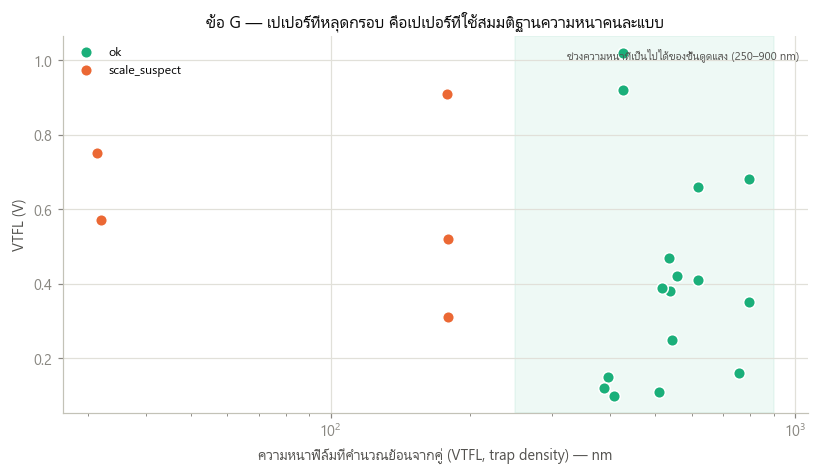

สรุป §4: ไม่มีคอลัมน์ที่ติดธงอยู่ใน feature set หรือ mediator ที่จะใช้จริง
        vtfl (28 device) เป็นค่าที่วัดตรงจากกราฟ ไม่ผ่านสมมติฐานความหนา -> ไม่ได้รับผลกระทบ
        => F, G, I ไม่บล็อกการสร้างโมเดล · ต้องเปิดเปเปอร์เฉพาะตอนจะรายงานค่าเหล่านี้เท่านั้น


In [6]:
# feature set ที่ตั้งใจใช้ (จาก DATA_PREPARATION.md + eda_htl_modification)
FEATURES = ["htl_mod_kind", "coat_htl", "coat_psk", "n_coating_layers", "etl_family",
            "a_Cs", "a_FA", "x_Br"]
MEDIATOR = ["vtfl"]
OUTCOME = ["pce", "voc", "jsc", "ff"]
FLAGGED = ["trap_density", "trap_density_electron", "defect_density_reported", "rrec", "rs",
           "trap_implied_thickness_nm"]

rows = []
for col in FLAGGED:
    rows.append(dict(คอลัมน์=col, n=int(tt[col].notna().sum()),
                     อยู่ใน_feature_set="ใช่" if col in FEATURES + MEDIATOR else "ไม่",
                     ธง={"trap_density": "trap_scale_flag", "trap_density_electron": "trap_scale_flag",
                         "defect_density_reported": "trap_scale_flag", "rrec": "rrec_scale_flag"}.get(col, "—")))
display(pd.DataFrame(rows).set_index("คอลัมน์"))

sus = tt[tt.trap_scale_flag == "scale_suspect"]
print(f"ข้อ G — trap_scale_flag = scale_suspect {len(sus)} device จาก {sus.paper.nunique()} เปเปอร์:")
display(sus[["device_id", "vtfl", "trap_density", "defect_density_reported",
             "trap_implied_thickness_nm"]].round(3).set_index("device_id"))

fig, ax = plt.subplots(figsize=(7.6, 4.4))
d = tt[tt.trap_implied_thickness_nm.notna()]
col = {"ok": C3, "scale_suspect": C2}
for f, sub in d.groupby("trap_scale_flag"):
    ax.scatter(sub.trap_implied_thickness_nm, sub.vtfl, s=58, color=col.get(f, MUTED),
               edgecolor="white", lw=1, label=f, zorder=3)
ax.axvspan(250, 900, color=C3, alpha=0.07, zorder=0)
ax.text(575, ax.get_ylim()[1] * 0.97, "ช่วงความหนาที่เป็นไปได้ของชั้นดูดแสง (250–900 nm)",
        ha="center", va="top", fontsize=7.4, color=INK2)
ax.set_xscale("log")
ax.set_xlabel("ความหนาฟิล์มที่คำนวณย้อนจากคู่ (VTFL, trap density) — nm")
ax.set_ylabel("VTFL (V)"); ax.legend(frameon=False, fontsize=8)
ax.set_title("ข้อ G — เปเปอร์ที่หลุดกรอบ คือเปเปอร์ที่ใช้สมมติฐานความหนาคนละแบบ")
plt.tight_layout(); plt.show()

print("สรุป §4: ไม่มีคอลัมน์ที่ติดธงอยู่ใน feature set หรือ mediator ที่จะใช้จริง")
print("        vtfl (28 device) เป็นค่าที่วัดตรงจากกราฟ ไม่ผ่านสมมติฐานความหนา -> ไม่ได้รับผลกระทบ")
print("        => F, G, I ไม่บล็อกการสร้างโมเดล · ต้องเปิดเปเปอร์เฉพาะตอนจะรายงานค่าเหล่านี้เท่านั้น")

## 5. EDA คอลัมน์ใหม่ 9 ตัว — ที่ `explore_prepared_v2` ยังไม่เคยเห็น

| คอลัมน์ | ชนิด | ใช้ทำอะไร |
|---|---|---|
| `jv_scan` | ป้าย | ทิศทางการวัดที่เลือกใช้ (คุมไม่ให้ปนชุด) |
| `trap_density_electron` | ค่า | trap ฝั่งอิเล็กตรอนที่แยกออกจากฝั่งโฮล |
| `sheet_resistance_htl` | ค่า | ความต้านทานแผ่นของฟิล์ม HTL (ย้ายออกจาก `rs`) |
| `defect_density_reported` | ค่า | ค่าที่เปเปอร์รายงานแต่ไม่รวมเข้า `trap_density` |
| `trap_implied_thickness_nm` · `trap_scale_flag` | ค่า + ธง | ความหนาที่คำนวณย้อนได้ + เทียบข้ามเปเปอร์ได้ไหม |
| `rrec_scale_flag` | ธง | Rrec หลุดสเกลจากกลุ่มไหม |
| `psk_spin_total_s` · `antisolvent_drop_frac_of_last` | ค่า | อีกการตีความของจังหวะหยด (§2) |

,บทบาท,n_device,n_paper,แปรผันภายในเปเปอร์,ใช้เป็น feature ได้ไหม
jv_scan,ป้ายที่มา,43,15,0,ไม่ใช่ feature (ป้ายที่มา)
psk_spin_total_s,knob (ตัวเลือก),42,14,0,ไม่ได้ (confound กับ paper)
antisolvent_drop_frac_of_last,knob (ตัวเลือก),31,11,0,ไม่ได้ (confound กับ paper)
trap_scale_flag,ธงวินิจฉัย,24,9,0,ไม่ใช่ feature (ธงวินิจฉัย)
trap_implied_thickness_nm,ตัวช่วยวินิจฉัย,21,8,8,ไม่ใช่ feature (ตัวช่วยวินิจฉัย)
rrec_scale_flag,ธงวินิจฉัย,16,7,0,ไม่ใช่ feature (ธงวินิจฉัย)
trap_density_electron,ค่าที่แยกออกมา,3,1,1,ไม่ใช่ feature (ค่าที่แยกออกมา)
defect_density_reported,ค่าที่กันไว้,2,1,1,ไม่ใช่ feature (ค่าที่กันไว้)
sheet_resistance_htl,ค่าที่แยกออกมา,2,1,1,ไม่ใช่ feature (ค่าที่แยกออกมา)


อ่านตาราง: 'แปรผันภายในเปเปอร์ > 0' ของคอลัมน์ที่ n น้อย (2-3 device จากเปเปอร์เดียว)
           ไม่ได้แปลว่าใช้เป็น feature ได้ — มันแปรผันเพราะมีอยู่เปเปอร์เดียวเท่านั้น


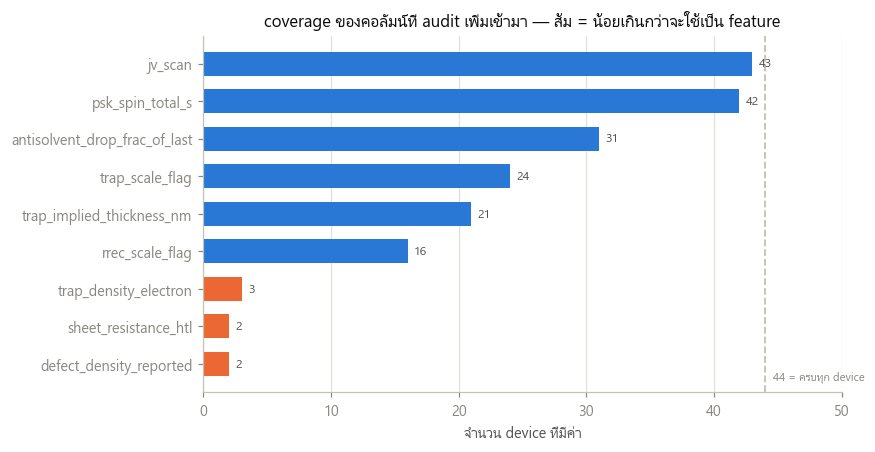

In [7]:
# บทบาทของแต่ละคอลัมน์ — ตัวไหน "อาจเป็น feature" ตัวไหนเป็นป้าย/ตัวช่วยวินิจฉัยตั้งแต่ต้น
ROLE = {"jv_scan": "ป้ายที่มา", "trap_scale_flag": "ธงวินิจฉัย", "rrec_scale_flag": "ธงวินิจฉัย",
        "trap_implied_thickness_nm": "ตัวช่วยวินิจฉัย", "defect_density_reported": "ค่าที่กันไว้",
        "sheet_resistance_htl": "ค่าที่แยกออกมา", "trap_density_electron": "ค่าที่แยกออกมา",
        "psk_spin_total_s": "knob (ตัวเลือก)", "antisolvent_drop_frac_of_last": "knob (ตัวเลือก)"}
NEW = list(ROLE)
cov = pd.DataFrame({
    "บทบาท": pd.Series(ROLE),
    "n_device": tt[NEW].notna().sum(),
    "n_paper": pd.Series({c: int(tt.loc[tt[c].notna(), "paper"].nunique()) for c in NEW}),
    "แปรผันภายในเปเปอร์": pd.Series({c: int((tt.groupby("paper")[c].nunique(dropna=True) > 1).sum()) for c in NEW}),
}).sort_values("n_device", ascending=False)


def usable(r):
    """เป็น feature ได้ต้องผ่าน 2 ด่าน: เป็น knob จริง + แปรผันภายในเปเปอร์ (ไม่งั้น LOPO แยกไม่ออกจาก paper)"""
    if not r["บทบาท"].startswith("knob"):
        return "ไม่ใช่ feature (" + r["บทบาท"] + ")"
    if r["แปรผันภายในเปเปอร์"] == 0:
        return "ไม่ได้ (confound กับ paper)"
    return "ได้"


cov["ใช้เป็น feature ได้ไหม"] = cov.apply(usable, axis=1)
display(cov)

print("อ่านตาราง: 'แปรผันภายในเปเปอร์ > 0' ของคอลัมน์ที่ n น้อย (2-3 device จากเปเปอร์เดียว)")
print("           ไม่ได้แปลว่าใช้เป็น feature ได้ — มันแปรผันเพราะมีอยู่เปเปอร์เดียวเท่านั้น")

fig, ax = plt.subplots(figsize=(8, 4.2))
s = cov.n_device.sort_values()
ax.barh(s.index, s.values, color=[C2 if v < 10 else C1 for v in s.values], height=0.64)
for i, v in enumerate(s.values):
    ax.text(v + 0.5, i, str(v), va="center", fontsize=8, color=INK2)
ax.axvline(44, color=BASE, lw=1.2, ls="--")
ax.text(44.6, -0.4, "44 = ครบทุก device", fontsize=7.4, color=MUTED)
ax.set_xlim(0, 50); ax.grid(axis="y", visible=False)
ax.set_xlabel("จำนวน device ที่มีค่า")
ax.set_title("coverage ของคอลัมน์ที่ audit เพิ่มเข้ามา — ส้ม = น้อยเกินกว่าจะใช้เป็น feature")
plt.tight_layout(); plt.show()

jv_scan: {'-': 30, 'RS': 13, nan: 1}

30 device ที่เปเปอร์ไม่ระบุทิศทางการวัด (10 เปเปอร์)
การแก้ข้อ O รับประกันได้แค่ว่า 'ไม่หยิบข้ามทิศทาง' ในเปเปอร์ที่ระบุทิศทางไว้
เปเปอร์ที่ไม่ระบุ ยังไม่รู้ว่าค่าที่รายงานเป็น RS หรือ FS -> เทียบ FF/hysteresis ข้ามเปเปอร์ต้องระวัง


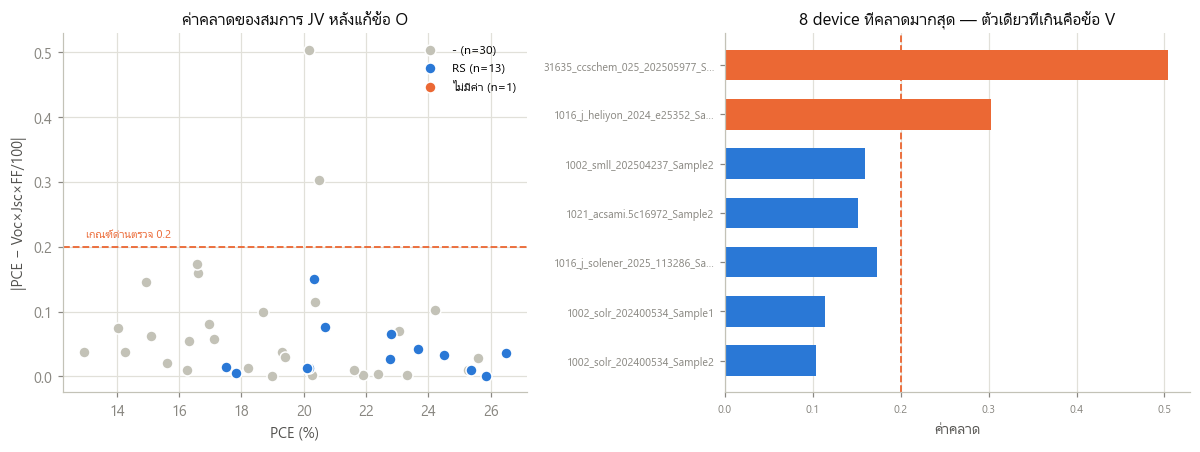

In [8]:
# jv_scan — ข้อจำกัดที่ยังเหลืออยู่หลังแก้ข้อ O
print("jv_scan:", tt.jv_scan.value_counts(dropna=False).to_dict())
unk = tt[tt.jv_scan == "-"]
print(f"\n{len(unk)} device ที่เปเปอร์ไม่ระบุทิศทางการวัด ({unk.paper.nunique()} เปเปอร์)")
print("การแก้ข้อ O รับประกันได้แค่ว่า 'ไม่หยิบข้ามทิศทาง' ในเปเปอร์ที่ระบุทิศทางไว้")
print("เปเปอร์ที่ไม่ระบุ ยังไม่รู้ว่าค่าที่รายงานเป็น RS หรือ FS -> เทียบ FF/hysteresis ข้ามเปเปอร์ต้องระวัง")

err = (tt.pce - tt.voc * tt.jsc * tt.ff / 100).abs()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

ax = axes[0]
for lab, sub in tt.assign(err=err).groupby(tt.jv_scan.fillna("ไม่มีค่า")):
    ax.scatter(sub.pce, sub.err, s=52, edgecolor="white", lw=1,
               color={"RS": C1, "-": BASE}.get(lab, C2), label=f"{lab} (n={len(sub)})", zorder=3)
ax.axhline(0.2, color=C2, lw=1.2, ls="--")
ax.text(13, 0.215, "เกณฑ์ด่านตรวจ 0.2", fontsize=7.4, color=C2)
ax.set_xlabel("PCE (%)"); ax.set_ylabel("|PCE − Voc×Jsc×FF/100|")
ax.legend(frameon=False, fontsize=8); ax.set_title("ค่าคลาดของสมการ JV หลังแก้ข้อ O")

ax = axes[1]
o = tt.assign(err=err).nlargest(8, "err")
ax.barh([short(d.replace("10_", "").replace("10.", ""), 30) for d in o.device_id][::-1],
        o.err.values[::-1], color=[C2 if v > 0.2 else C1 for v in o.err.values[::-1]], height=0.62)
ax.axvline(0.2, color=C2, lw=1.2, ls="--")
ax.set_xlabel("ค่าคลาด"); ax.grid(axis="y", visible=False); ax.tick_params(labelsize=7)
ax.set_title("8 device ที่คลาดมากสุด — ตัวเดียวที่เกินคือข้อ V")
plt.tight_layout(); plt.show()

## 6. อะไรเปลี่ยนจาก `explore_prepared_v2` — ตัวเลขที่ต้องอัปเดต

v2 คำนวณตอน `voc/jsc/ff` ของ 5 device ยังปนทิศทางสแกน และ `rs` ยังมีความต้านทานแผ่นปนอยู่
สหสัมพันธ์ naive ที่ v2 รายงานจึงเปลี่ยนไปบ้าง — ตารางนี้คือชุดที่ถูกต้อง ณ ตอนนี้

,pce,voc,jsc,ff,vtfl
psk_spin_rpm,0.002,-0.162,0.193,-0.048,0.631
psk_anneal_C,0.149,0.034,0.163,0.086,-0.375
psk_anneal_time_s,0.150,0.435,-0.135,0.299,0.044
antisolvent_vol_uL,-0.171,-0.148,-0.175,-0.152,0.156
antisolvent_timing_s,0.428,0.520,0.350,0.248,-0.281
htl_anneal_C,-0.561,-0.646,-0.291,-0.728,-0.284
psk_spin_last_s,0.386,0.270,0.239,0.361,-0.525
antisolvent_drop_frac_of_total,0.525,0.466,0.316,0.482,-0.068
psk_spin_total_s,0.252,0.124,0.129,0.424,-0.072
antisolvent_drop_frac_of_last,0.497,0.388,0.291,0.496,0.079


,v2_รายงานไว้,ค่าปัจจุบัน,ต่าง,สถานะ
คู่,,,,
htl_anneal_C ~ ff,-0.74,-0.728,0.012,เท่าเดิม
htl_anneal_C ~ voc,-0.64,-0.646,-0.006,เท่าเดิม
psk_spin_rpm ~ vtfl,0.57,0.631,0.061,ต้องอัปเดต
antisolvent_timing_s ~ voc,0.52,0.520,0.000,เท่าเดิม
psk_anneal_C ~ vtfl,-0.38,-0.375,0.005,เท่าเดิม


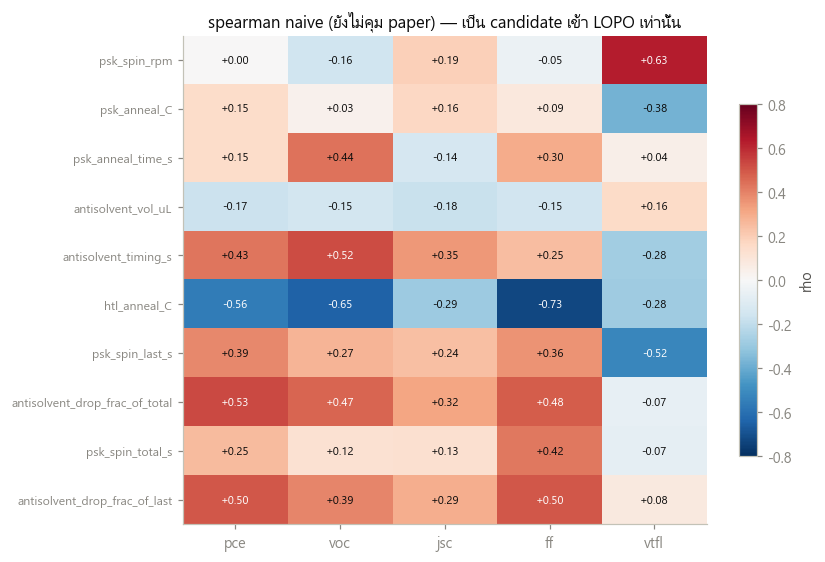

คู่ที่โดดใหม่หลังแก้ข้อมูล (v2 ไม่ได้รายงานไว้):
  htl_anneal_C ~ pce: -0.561
  antisolvent_drop_frac_of_total ~ pce: +0.525
  psk_spin_last_s ~ vtfl: -0.525
  antisolvent_drop_frac_of_last ~ pce: +0.497

⚠️ ทั้งหมดนี้ยังไม่คุม paper และ knob เหล่านี้แปรผันภายในเปเปอร์ 0/15
   -> อ่านเป็น 'ความต่างระหว่างห้องแล็บ' ไม่ใช่ผลของ knob


In [9]:
KNOBS = ["psk_spin_rpm", "psk_anneal_C", "psk_anneal_time_s", "antisolvent_vol_uL",
         "antisolvent_timing_s", "htl_anneal_C", "psk_spin_last_s",
         "antisolvent_drop_frac_of_total", "psk_spin_total_s", "antisolvent_drop_frac_of_last"]
YS = ["pce", "voc", "jsc", "ff", "vtfl"]
M = pd.DataFrame({y: {k: spearman(tt[k], tt[y])[0] for k in KNOBS} for y in YS})
display(M.round(3))

# เทียบกับตัวเลขที่ v2 / DATA_PREPARATION.md รายงานไว้
V2_REPORTED = {("htl_anneal_C", "ff"): -0.74, ("htl_anneal_C", "voc"): -0.64,
               ("psk_spin_rpm", "vtfl"): +0.57, ("antisolvent_timing_s", "voc"): +0.52,
               ("psk_anneal_C", "vtfl"): -0.38}
rows = []
for (k, y), old in V2_REPORTED.items():
    new = M.loc[k, y]
    rows.append(dict(คู่=f"{k} ~ {y}", v2_รายงานไว้=old, ค่าปัจจุบัน=round(new, 3),
                     ต่าง=round(new - old, 3),
                     สถานะ="ต้องอัปเดต" if abs(new - old) >= 0.03 else "เท่าเดิม"))
display(pd.DataFrame(rows).set_index("คู่"))

fig, ax = plt.subplots(figsize=(7.8, 5.2))
im = ax.imshow(M.values, cmap="RdBu_r", vmin=-0.8, vmax=0.8, aspect="auto")
ax.set_xticks(range(len(YS)), YS); ax.set_yticks(range(len(KNOBS)), KNOBS, fontsize=8)
for i in range(len(KNOBS)):
    for j in range(len(YS)):
        v = M.values[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=7.4,
                    color="white" if abs(v) > 0.45 else INK)
ax.grid(False)
ax.set_title("spearman naive (ยังไม่คุม paper) — เป็น candidate เข้า LOPO เท่านั้น")
fig.colorbar(im, ax=ax, shrink=0.72, label="rho")
plt.tight_layout(); plt.show()

print("คู่ที่โดดใหม่หลังแก้ข้อมูล (v2 ไม่ได้รายงานไว้):")
flat = M.stack().dropna().abs().sort_values(ascending=False)
for (k, y), v in flat.head(8).items():
    if (k, y) not in V2_REPORTED:
        print(f"  {k} ~ {y}: {M.loc[k, y]:+.3f}")
print("\n⚠️ ทั้งหมดนี้ยังไม่คุม paper และ knob เหล่านี้แปรผันภายในเปเปอร์ 0/15")
print("   -> อ่านเป็น 'ความต่างระหว่างห้องแล็บ' ไม่ใช่ผลของ knob")

In [10]:
# ซิงก์ระหว่างเอกสารกับข้อมูล — ตัวเลขที่ DATA_PREPARATION.md เขียนไว้ ต้องตรงกับไฟล์จริงเสมอ
# ถ้าขึ้น "ต้องอัปเดต" แปลว่ารัน pipeline แล้วค่าเปลี่ยน แต่ยังไม่ได้แก้เอกสาร
COV_DOC = {"voc": 43, "jsc": 43, "ff": 43, "pce": 42, "rs": 20, "trap_density": 22, "vtfl": 28,
           "rrec": 16, "retention_25c": 16, "degradation_rate": 16, "psk_spin_rpm": 44,
           "psk_anneal_C": 42, "htl_anneal_C": 42, "antisolvent_drop_frac_of_total": 31}
rows = []
for c, old in COV_DOC.items():
    new = int(tt[c].notna().sum())
    rows.append(dict(คอลัมน์=c, เอกสารเขียนไว้=old, ปัจจุบัน=new, ต่าง=new - old,
                     สถานะ="ต้องอัปเดต" if new != old else "เท่าเดิม"))
display(pd.DataFrame(rows).set_index("คอลัมน์"))

print(f"pce มี {int(tt.pce.notna().sum())} device ส่วน voc/jsc/ff มี {int(tt.voc.notna().sum())}")
print("  ต่างกัน 1 เพราะ nanoen_Sample1 ไม่รายงาน PCE (เอกสารระบุหมายเหตุนี้ไว้แล้ว — ใช้ voc×jsc×ff/100 แทนได้)")
print("  ส่วน adma_Sample2 ไม่มีค่า JV เลยทั้ง 4 ตัว")

,เอกสารเขียนไว้,ปัจจุบัน,ต่าง,สถานะ
คอลัมน์,,,,
voc,43,43,0,เท่าเดิม
jsc,43,43,0,เท่าเดิม
ff,43,43,0,เท่าเดิม
pce,42,42,0,เท่าเดิม
rs,20,20,0,เท่าเดิม
trap_density,22,22,0,เท่าเดิม
vtfl,28,28,0,เท่าเดิม
rrec,16,16,0,เท่าเดิม
retention_25c,16,16,0,เท่าเดิม


pce มี 42 device ส่วน voc/jsc/ff มี 43
  ต่างกัน 1 เพราะ nanoen_Sample1 ไม่รายงาน PCE (เอกสารระบุหมายเหตุนี้ไว้แล้ว — ใช้ voc×jsc×ff/100 แทนได้)
  ส่วน adma_Sample2 ไม่มีค่า JV เลยทั้ง 4 ตัว


## 7. ทะเบียนสิ่งที่เหลือ — ส่งต่อรอบหน้า

แยกให้ชัดว่าอะไร **บล็อกโมเดล** อะไร **บล็อกแค่การเขียน methods** และอะไรเป็น **หนี้เอกสาร**

In [11]:
BACKLOG = [
    dict(ข้อ="V", เรื่อง="PCE ของ ccschem_Sample1 ไม่ลงตัว 0.50",
         ต้องใช้="อ่านเปเปอร์แล้ว ✓", บล็อกโมเดล="ไม่",
         สถานะ="ปิดแล้ว — เนื้อความเปเปอร์เขียน 1.15 / 23.53 / 76.40 / 20.17 ตรงกับไฟล์เรา 100% "
                "ความไม่สอดคล้องอยู่ในตัวเปเปอร์เอง (ซ้ำทั้ง Table S3 และเนื้อความ) ไม่ใช่ความผิดของการสกัด",
         ทำอะไรต่อ="เก็บ 20.17 ตามต้นฉบับ · เขียน methods ว่าเป็น inconsistency ของเปเปอร์ (§3 พิสูจน์แล้วว่าไม่ใช่การปัดเศษ)"),
    dict(ข้อ="L", เรื่อง="จุดอ้างอิงจังหวะหยด antisolvent",
         ต้องใช้="acsami_5c15868, acsami.5c16972", บล็อกโมเดล="ไม่",
         สถานะ="แก้แล้ว + มีหลักฐานเชิงถ้อยคำ — ccschem เขียนว่า dropped at 30 s after the start of "
                "the spinning process = นับจากเริ่มโปรแกรมทั้งหมด ตรงกับนิยาม of_total",
         ทำอะไรต่อ="ยืนยันซ้ำกับ acsami_5c15868 (เปเปอร์เดียวที่ตัวเลขต่างกันจริง) ก่อนเขียน methods"),
    dict(ข้อ="F", เรื่อง="Defect density ของ solr_202200422",
         ต้องใช้="Fig. 2c ของเปเปอร์", บล็อกโมเดล="ไม่",
         สถานะ="อยู่นอก feature set (§4) · ติดธง scale_suspect พร้อมเหตุผลในไฟล์",
         ทำอะไรต่อ="ตรวจสมมติฐานความหนาที่ Fig. 2c ใช้ ถ้าจะรายงานค่านี้"),
    dict(ข้อ="I", เรื่อง="นิยาม Rrec ของ acsami_4c14300",
         ต้องใช้="Table S2 ของเปเปอร์", บล็อกโมเดล="ไม่",
         สถานะ="แคบลง — ccschem ยืนยันหน่วยเป็น Ω ธรรมดา (179/372/488) ห่างจาก acsami_4c14300 ~1e5 เท่า "
                "· แก้กติกาธงจากรายอุปกรณ์เป็นรายเปเปอร์ (เจอบั๊กตอนเติมค่า 179)",
         ทำอะไรต่อ="เปิด Table S2 ของ acsami_4c14300 ดูว่าเป็น Ω·cm² หรือ นิยามคนละแบบ"),
    dict(ข้อ="W1", เรื่อง="30 device ไม่ระบุทิศทางการวัด J–V",
         ต้องใช้="เปเปอร์ต้นฉบับ 30 device", บล็อกโมเดล="ไม่",
         สถานะ="พบใน §5 · ccschem 3 device ยืนยันแล้วว่าเปเปอร์ไม่ระบุจริง (ไม่ใช่ข้อมูลตกหล่น) เหลือ 27",
         ทำอะไรต่อ="อย่าตีความ FF/hysteresis ข้ามเปเปอร์ · ถ้าจะใช้ ต้องไล่เก็บทิศทางเพิ่ม"),
    dict(ข้อ="W2", เรื่อง="ตัวเลข coverage และสหสัมพันธ์ในเอกสารเป็นชุดก่อนแก้",
         ต้องใช้="—", บล็อกโมเดล="ไม่",
         สถานะ="แก้แล้ว — DATA_PREPARATION.md + reports/report.html (702×72, rs 20, knob 31–44)",
         ทำอะไรต่อ="ตรวจซ้ำใน §6 ทุกครั้งที่รัน pipeline ใหม่"),
    dict(ข้อ="K", เรื่อง="ชื่อ mobility ไม่แยกตามชั้น",
         ต้องใช้="เปเปอร์ smll / jechem / solr_202200422", บล็อกโมเดล="ไม่",
         สถานะ="แก้บางส่วน — recheck §8.8b เติม layer=HTL 3 แถวที่ remarks ระบุ stack ไม่มี perovskite · อีก 6 แถวติดธง",
         ทำอะไรต่อ="เปิดเปเปอร์ดูว่า 6 แถวที่เหลือวัดจากชั้นไหน · ระหว่างนี้ห้ามเทียบ mobility ข้ามเปเปอร์"),
    dict(ข้อ="X1", เรื่อง="processed/prepared/ ยังมีบั๊กที่ recheck ปะให้ทีหลัง",
         ต้องใช้="—", บล็อกโมเดล="ไม่",
         สถานะ="อ่านครบ 102 เซลล์แล้ว (§8) — mobility ×1e4, Rs, VBM, JV ยังผิดใน prepared/",
         ทำอะไรต่อ="ใช้ prepared_v2/ เท่านั้น · ถ้าจะแก้ที่ราก ให้ย้าย PARAM/SIGN/UNIT fix ไป column_prepare"),
    dict(ข้อ="X2", เรื่อง="after_col_prepare.ipynb (44×39) สร้างจาก prepared/ + aggfunc='max'",
         ต้องใช้="—", บล็อกโมเดล="ไม่",
         สถานะ="พบใน §8 — เป็นบั๊ก Champion/Average ตัวเดิมที่ recheck §7 แก้ไปแล้ว",
         ทำอะไรต่อ="ห้ามอ้างตัวเลขจากโน้ตบุ๊กนั้น · ถ้ายังใช้อยู่ ให้ชี้ไป prepared_v2/target_table.csv"),
    dict(ข้อ="X3", เรื่อง="decompose() อ่านแค่ชื่อ property ไม่อ่าน remarks",
         ต้องใช้="—", บล็อกโมเดล="ไม่",
         สถานะ="พบใน §8 — เป็นรากเดียวของ audit ข้อ D, E, J, K ทั้งสี่",
         ทำอะไรต่อ="ให้ decompose() อ่าน remarks เพื่อดึงชั้น แทนการไล่แก้ทีละเคสที่ recheck"),
    dict(ข้อ="X4/X5", เรื่อง="is_num ถูกนิยามซ้ำแบบหลวม · classify_material_format ซ้ำ 2 ครั้ง",
         ต้องใช้="—", บล็อกโมเดล="ไม่",
         สถานะ="ความเสี่ยงแฝง — ยังไม่กระทบข้อมูลชุดนี้ (0 แถวต่าง)",
         ทำอะไรต่อ="ลบนิยามซ้ำตอนแตะ column_prepare ครั้งถัดไป"),
]
backlog = pd.DataFrame(BACKLOG)
display(backlog.set_index("ข้อ"))

AUDIT = ROOT / "processed" / "audit"
AUDIT.mkdir(parents=True, exist_ok=True)
gate.to_csv(AUDIT / "audit_v3_gate.csv", index=False, encoding="utf-8-sig")
backlog.to_csv(AUDIT / "audit_v3_backlog.csv", index=False, encoding="utf-8-sig")
g.round(4).to_csv(AUDIT / "audit_v3_antisolvent_interpretation.csv", encoding="utf-8-sig")
print("เขียนแล้ว:")
for f in ["audit_v3_gate.csv", "audit_v3_backlog.csv", "audit_v3_antisolvent_interpretation.csv"]:
    print("  processed/audit/" + f)
print(f"\nไม่มีข้อไหนบล็อกการสร้างโมเดล — {int((backlog.บล็อกโมเดล == 'ไม่').sum())}/{len(backlog)} ข้อ")

,เรื่อง,ต้องใช้,บล็อกโมเดล,สถานะ,ทําอะไรต่อ
ข้อ,,,,,
V,PCE ของ ccschem_Sample1 ไม่ลงตัว 0.50,อ่านเปเปอร์แล้ว ✓,ไม่,ปิดแล้ว — เนื้อความเปเปอร์เขียน 1.15 / 23.53 /...,เก็บ 20.17 ตามต้นฉบับ · เขียน methods ว่าเป็น ...
L,จุดอ้างอิงจังหวะหยด antisolvent,"acsami_5c15868, acsami.5c16972",ไม่,แก้แล้ว + มีหลักฐานเชิงถ้อยคำ — ccschem เขียนว...,ยืนยันซ้ำกับ acsami_5c15868 (เปเปอร์เดียวที่ตั...
F,Defect density ของ solr_202200422,Fig. 2c ของเปเปอร์,ไม่,อยู่นอก feature set (§4) · ติดธง scale_suspect...,ตรวจสมมติฐานความหนาที่ Fig. 2c ใช้ ถ้าจะรายงาน...
I,นิยาม Rrec ของ acsami_4c14300,Table S2 ของเปเปอร์,ไม่,แคบลง — ccschem ยืนยันหน่วยเป็น Ω ธรรมดา (179/...,เปิด Table S2 ของ acsami_4c14300 ดูว่าเป็น Ω·c...
W1,30 device ไม่ระบุทิศทางการวัด J–V,เปเปอร์ต้นฉบับ 30 device,ไม่,พบใน §5 · ccschem 3 device ยืนยันแล้วว่าเปเปอร...,อย่าตีความ FF/hysteresis ข้ามเปเปอร์ · ถ้าจะใช...
W2,ตัวเลข coverage และสหสัมพันธ์ในเอกสารเป็นชุดก่...,—,ไม่,แก้แล้ว — DATA_PREPARATION.md + reports/report...,ตรวจซ้ำใน §6 ทุกครั้งที่รัน pipeline ใหม่
K,ชื่อ mobility ไม่แยกตามชั้น,เปเปอร์ smll / jechem / solr_202200422,ไม่,แก้บางส่วน — recheck §8.8b เติม layer=HTL 3 แถ...,เปิดเปเปอร์ดูว่า 6 แถวที่เหลือวัดจากชั้นไหน · ...
X1,processed/prepared/ ยังมีบั๊กที่ recheck ปะให้...,—,ไม่,"อ่านครบ 102 เซลล์แล้ว (§8) — mobility ×1e4, Rs...",ใช้ prepared_v2/ เท่านั้น · ถ้าจะแก้ที่ราก ให้...
X2,after_col_prepare.ipynb (44×39) สร้างจาก prepa...,—,ไม่,พบใน §8 — เป็นบั๊ก Champion/Average ตัวเดิมที่...,ห้ามอ้างตัวเลขจากโน้ตบุ๊กนั้น · ถ้ายังใช้อยู่ ...


เขียนแล้ว:
  processed/audit/audit_v3_gate.csv
  processed/audit/audit_v3_backlog.csv
  processed/audit/audit_v3_antisolvent_interpretation.csv

ไม่มีข้อไหนบล็อกการสร้างโมเดล — 11/11 ข้อ


## 8. ข้อ X — ตรวจตรรกะใน `column_prepare.ipynb` ทีละเซลล์ (102 เซลล์)

audit เดิมเขียนไว้ว่า *"ตรรกะการคลีนใน column_prepare ทั้ง 102 เซลล์ ยังไม่ได้อ่านทีละเซลล์"* — อ่านครบแล้ว

**โครงสร้างแข็งแรง**: มีด่านตรวจปิดท้ายทุกช่วง · คอลัมน์ดิบไม่เคยถูกแก้หลังจบช่วง 1 (เพิ่ม `_parsed`/`_note` แทน) ·
เขียนดิสก์จุดเดียว แล้วอ่านกลับมาเทียบกับตารางในหน่วยความจำทีละเซลล์ · ทุกการตีความถูกบันทึกลง `audit/`

**สิ่งที่พบ 5 ข้อ — เรียงตามความสำคัญ:**

| # | เรื่อง | ผลตอนนี้ |
|---|---|---|
| **X1** | **`processed/prepared/` ยังมีบั๊กที่ recheck แก้ให้ทีหลัง** — mobility 3 แถวยังผิด ×10⁴, `Rs` ยังปนความต้านทานแผ่น, VBM ยังเซ็นบวก, JV ยังปนชุด/ทิศทาง | ⚠️ ใครอ่าน `prepared/` ตรง ๆ ได้ค่าผิด |
| **X2** | **`after_col_prepare.ipynb` (44×39) อ่าน `prepared/`** และ pivot ด้วย `aggfunc="max"` ต่อ `base_property` = บั๊ก Champion/Average ตัวเดิมเป๊ะ ๆ | ⚠️ ตัวเลขในโน้ตบุ๊กนั้นห้ามนำไปอ้าง |
| **X3** | **`decompose()` อ่านแค่ "ชื่อ" ของ property** รู้จัก prefix แค่ `HTL`/`PSK`/`PVK` · ข้อมูลชั้นของ mobility/Rs/VBM อยู่ในช่อง `remarks` ซึ่งไม่เคยถูกอ่าน | **รากเดียวของ audit ข้อ D, E, J, K ทั้งสี่ข้อ** |
| **X4** | `is_num` ถูกนิยามซ้ำที่เซลล์ 36 — จากเดิม regex เข้ม กลายเป็น `float()` แบบหลวม (รับ `"nan"`, `"inf"`, `"1_0"`) และมีผลกับทุกเซลล์หลังจากนั้น | ยังไม่กระทบ (0 แถวต่าง) — ความเสี่ยงแฝง |
| **X5** | `classify_material_format` ถูกนิยาม 2 ครั้ง (เซลล์ 30 แล้วเซลล์ 31 คนละกติกา) ผลที่พิมพ์ในเซลล์ 30 จึงไม่ตรงกับที่ parser ใช้จริง | อยู่ในบล็อก prototype ที่ติดป้าย "ไม่ได้ใช้ต่อ" แล้ว |

> **X3 คือข้อที่มีค่าที่สุด** — audit เจอ D, E, J, K แยกกันเป็น 4 ข้อ แต่ทั้งสี่คืออาการเดียวกัน:
> ชื่อ property ไม่พอจะบอกว่าค่านั้นวัดจากชั้นไหน และ `remarks` ที่บอกไว้ไม่เคยถูกใช้
> ถ้าจะแก้ที่ราก ต้องให้ `decompose()` อ่าน `remarks` ด้วย ไม่ใช่ไล่แก้ทีละเคสที่ recheck

In [12]:
# X1 — วัดความต่างจริงระหว่าง prepared/ (ผลของ column_prepare ล้วน) กับ prepared_v2/ (หลัง recheck)
V1 = ROOT / "processed" / "prepared"
p1 = pd.read_csv(V1 / "properties.csv")
p2 = prop

rows = []
mob = p1.base_property.astype(str).str.contains("mobil", case=False, na=False)
mob_bad = p1[mob & p1.unit.astype(str).str.startswith("m2")]
rows.append(dict(เรื่อง="mobility m2 ที่ยังไม่คูณ 1e4 ใน value_parsed",
                 prepared=f"{len(mob_bad)} แถวยังผิด", prepared_v2="ซิงก์แล้ว (recheck §8.7)"))
rows.append(dict(เรื่อง="VBM ที่เครื่องหมายลบยังหาย",
                 prepared=f"{int((p1[p1.base_property == 'VBM'].value_parsed > 0).sum())} แถว",
                 prepared_v2=f"{int((p2[p2.base_property == 'VBM'].value_parsed > 0).sum())} แถว"))
rows.append(dict(เรื่อง="ชื่อ VBM ที่ยังไม่แยกเป็น 2 ปริมาณ",
                 prepared=f"{int((p1.base_property == 'VBM offset from EF').sum())} แถวที่แยกแล้ว",
                 prepared_v2=f"{int((p2.base_property == 'VBM offset from EF').sum())} แถวที่แยกแล้ว"))
rows.append(dict(เรื่อง="mobility ที่ระบุชั้นได้",
                 prepared=f"{int(p1[mob].layer.notna().sum())}/{int(mob.sum())}",
                 prepared_v2=f"{int(p2[p2.base_property.astype(str).str.contains('mobil', case=False, na=False)].layer.notna().sum())}/9"))
display(pd.DataFrame(rows).set_index("เรื่อง"))

# gate: ถ้าวันหนึ่ง column_prepare ถูกแก้ที่ราก ค่าพวกนี้จะเท่ากัน แล้วเซลล์นี้จะเตือนให้ลบข้อ X1 ทิ้ง
_still_broken = len(mob_bad) > 0
print("สรุป X1:", "prepared/ ยังมีบั๊กที่ recheck ปะให้ทีหลัง — ห้ามใช้ prepared/ เป็นแหล่งข้อมูล"
      if _still_broken else "prepared/ ถูกแก้ที่รากแล้ว — ปรับข้อ X1 ในทะเบียนได้")

# X3 — วัดขนาดของปัญหา "ชื่อไม่บอกชั้น"
AMBIG = ["mobility", "Rs", "Rsh", "Conductivity", "VBM", "Fermi level", "Work Function", "Bandgap"]
amb = p2[p2.base_property.isin(AMBIG)]
print()
print("X3: property ที่ค่าขึ้นกับชั้นแต่ decompose() ระบุชั้นให้ไม่ได้จากชื่อ")
display(amb.groupby("base_property").agg(
    n_แถว=("device_id", "size"), n_device=("device_id", "nunique"),
    ระบุชั้นแล้ว=("layer", lambda s: int(s.notna().sum())),
    มี_remarks=("remarks", lambda s: int(s.notna().sum()))).sort_values("n_แถว", ascending=False))
print("คอลัมน์ 'มี remarks' คือจำนวนแถวที่ต้นฉบับ *บอกชั้นไว้แล้ว* แต่ decompose() ไม่เคยอ่าน")

,prepared,prepared_v2
เรื่อง,,
mobility m2 ที่ยังไม่คูณ 1e4 ใน value_parsed,3 แถวยังผิด,ซิงก์แล้ว (recheck §8.7)
VBM ที่เครื่องหมายลบยังหาย,4 แถว,0 แถว
ชื่อ VBM ที่ยังไม่แยกเป็น 2 ปริมาณ,0 แถวที่แยกแล้ว,3 แถวที่แยกแล้ว
mobility ที่ระบุชั้นได้,0/9,3/9


สรุป X1: prepared/ ยังมีบั๊กที่ recheck ปะให้ทีหลัง — ห้ามใช้ prepared/ เป็นแหล่งข้อมูล

X3: property ที่ค่าขึ้นกับชั้นแต่ decompose() ระบุชั้นให้ไม่ได้จากชื่อ


,n_แถว,n_device,ระบุชั้นแล้ว,มี_remarks
base_property,,,,
Rs,22,22,0,16
VBM,12,12,0,10
Work Function,10,10,0,8
mobility,9,9,3,7
Fermi level,7,7,0,3
Conductivity,4,4,0,4
Rsh,2,2,0,2
Bandgap,1,1,1,1


คอลัมน์ 'มี remarks' คือจำนวนแถวที่ต้นฉบับ *บอกชั้นไว้แล้ว* แต่ decompose() ไม่เคยอ่าน


## 9. ตรวจกับเปเปอร์ต้นฉบับฉบับที่ 2 — `ccschem` (CCS Chem. 2026, 8, 1964-1974)

เปเปอร์นี้เป็น **diamond open access** จึงเปิดอ่านได้ทั้งฉบับ ไล่เทียบทุกค่าที่สกัดมา

**ตรงหมด 30 ค่า** — process 14 ค่า (ล้าง / พลาสมา / NiOx / PSK / PEAI / PCBM / BCP / Ag) - สูตรเคมี -
VTFL + trap density 3 คู่ - VBM 3 ค่า - retention 6 ค่า - Voc/Jsc/FF/PCE ทั้ง 3 device

**เจอเพิ่ม 4 อย่างที่แก้แล้ว** (recheck §4.0c) และ **1 บั๊กของกติกาเราเอง**:

| # | เจออะไร | หลักฐานในเปเปอร์ | ผล |
|---|---|---|---|
| 1 | `Work Function` ของ Sample1 กรอก **4.52** | *"the VB edge of NiOx was located at -5.02 eV, with a WF of **4.75** eV"* | แก้เป็น 4.75 |
| 2 | ชื่อ `WF` กับ `Work Function` อยู่ในเปเปอร์เดียวกัน | Sample1 ใช้ชื่อเต็ม Sample2/3 ใช้ตัวย่อ | ยุบเป็นชื่อเดียว — **สำคัญเพราะด่านตรวจ §9.5 ไล่ตามชื่อ แถว `WF` จึงเคยหลุดการตรวจ** |
| 3 | `Rrec` ของ Sample1 **หายไปทั้งค่า** | *"increase in the composite resistance (Rrec) from **179** to 372 (2PACz) and 488 Ohm"* | เติม 179 - `rrec` 15 to **16** |
| 4 | เงื่อนไข retention ของ Sample1/2 ไม่ได้กรอกอุณหภูมิ | *"93% ... over 1000 h of storage at **room temperature** under N2. In contrast, ... **90%** and **82%**"* | เติม 25 C - `retention_25c` 14 to **16** และ ccschem มีคู่เทียบครบ |
| 5 | **กติกา `rrec_scale_flag` ผิดความหมาย** | 179 ถูกติดธง ขณะที่ 372/488 จาก**รูปเดียวกัน**ไม่ติด | เปลี่ยนจากวัดรายอุปกรณ์เป็น **รายเปเปอร์** + assert ว่าธงต้องเท่ากันทั้งเปเปอร์ |

> ข้อ 5 เป็นบั๊กที่โผล่มาเพราะ**เติมข้อมูลจริงเข้าไป** — สเกลเป็นคุณสมบัติของ *นิยามที่เปเปอร์ใช้*
> ไม่ใช่ของอุปกรณ์ กติกาเดิมจึงแบ่งเปเปอร์เดียวออกเป็นสองฝั่งได้

**ข้อ L ได้หลักฐานเชิงถ้อยคำด้วย**: เปเปอร์เขียนว่า chlorobenzene *"was dropped at 30 s after the start of
**the spinning process**"* — คือนับจากเริ่ม**โปรแกรมทั้งหมด** ตรงกับนิยามของ `antisolvent_drop_frac_of_total`
(เปเปอร์นี้ spin ขั้นเดียว 40 s ตัวเลขจึงเท่ากันทั้งสองแบบ แต่ถ้อยคำชี้ขาดเรื่อง*จุดอ้างอิง*ได้)

In [13]:
# ยืนยันว่าการแก้จากเปเปอร์เข้ามาครบ และไม่ทำให้อย่างอื่นพัง
CC = "10_31635_ccschem_025_202505977"
cc = tt[tt.device_id.str.startswith(CC)]
display(cc[["device_id", "voc", "jsc", "ff", "pce", "vtfl", "rrec",
            "rrec_scale_flag", "retention_25c"]].set_index("device_id"))

wf = prop[(prop.base_property == "Work Function") & prop.device_id.str.startswith(CC)]
print("Work Function หลังยุบชื่อ + แก้ค่า:",
      {r.device_id.split("_Sample")[1]: r.value_parsed for r in wf.itertuples()})
print("   เปเปอร์ระบุ: NiOx 4.75 | 2PACz 4.77 | 2Br-4PADMAc 5.04")

print()
print("ธง rrec ต้องเท่ากันทั้งเปเปอร์ (ไม่งั้นแปลว่ากลับไปวัดรายอุปกรณ์):")
_rr = tt[tt.rrec.notna()].copy()
_g = _rr.groupby("paper").rrec_scale_flag.agg(["nunique", "first", "size"])
display(_g.rename(columns={"nunique": "ธงต่างกันกี่แบบ", "first": "ธง", "size": "n_device"}))
assert (_g["nunique"] == 1).all(), "ธง rrec ไม่สม่ำเสมอภายในเปเปอร์"

print()
print(f"coverage หลังเติมค่าจากเปเปอร์: rrec {int(tt.rrec.notna().sum())} | "
      f"retention_25c {int(tt.retention_25c.notna().sum())} device")
print("ผลต่อการวิเคราะห์: retention เทียบได้ 3 -> 4 เปเปอร์ (ดู eda_htl_modification §8)")

,voc,jsc,ff,pce,vtfl,rrec,rrec_scale_flag,retention_25c
device_id,,,,,,,,
10_31635_ccschem_025_202505977_Sample1,1.15,23.53,76.40,20.17,0.15,179.0,ok,82.0
10_31635_ccschem_025_202505977_Sample2,1.19,24.23,79.77,23.07,0.12,372.0,ok,90.0
10_31635_ccschem_025_202505977_Sample3,1.20,25.48,82.71,25.28,0.10,488.0,ok,93.0


Work Function หลังยุบชื่อ + แก้ค่า: {'1': 4.75, '2': 4.77, '3': 5.04}
   เปเปอร์ระบุ: NiOx 4.75 | 2PACz 4.77 | 2Br-4PADMAc 5.04

ธง rrec ต้องเท่ากันทั้งเปเปอร์ (ไม่งั้นแปลว่ากลับไปวัดรายอุปกรณ์):


,ธงต่างกันกี่แบบ,ธง,n_device
paper,,,
10.1016j.nanoen.2021.106285,1,ok,3
10.1021_acsami.5c16972,1,ok,3
10_1002_solr_202400534,1,ok,2
10_1002adma_202507730,1,ok,1
10_1021_acsami_4c14300,1,scale_suspect,2
10_1021_acsami_5c15868,1,ok,2
10_31635_ccschem_025_202505977,1,ok,3



coverage หลังเติมค่าจากเปเปอร์: rrec 16 | retention_25c 16 device
ผลต่อการวิเคราะห์: retention เทียบได้ 3 -> 4 เปเปอร์ (ดู eda_htl_modification §8)


## สรุป — อ่านอะไรจากโน้ตบุ๊กนี้ได้บ้าง

1. **การแก้จาก audit ทั้ง 17 ข้อยังอยู่ครบในไฟล์บนดิสก์** (§1) — ด่านตรวจ 20 ข้อผ่าน ไม่มี FAIL
   ถ้ารัน pipeline ใหม่แล้วเซลล์ §1 แดง แปลว่าการแก้หายไป ต้องหยุดก่อนใช้ข้อมูล

2. **ข้อ V ปิดได้ในเชิงผลลัพธ์** (§3) — ไม่ว่าจะใช้ 20.17 หรือ 20.67 ค่ากลาง ΔPCE = +2.09 · 11/11 · p = 0.001 เท่ากันเป๊ะ
   และพิสูจน์ได้ว่าส่วนต่าง 0.50 **ไม่ใช่การปัดเศษ** (ปัดเศษอธิบายได้แค่ ±0.10) — คำอธิบายเดิมในเอกสารต้องแก้

3. **ข้อ L แก้แล้ว** (§2) — การตีความเดิมบังคับให้ `acsami_5c15868` หยด antisolvent ตอนวินาทีที่หยุดปั่นพอดี
   ซึ่งเป็นไปไม่ได้ · `recheck §9` สลับตัวหลักเป็น **`antisolvent_drop_frac_of_total`** แล้ว
   พร้อมตั้งชื่อคอลัมน์ตามตัวหาร (`_of_total` / `_of_last`) เลิกใช้ชื่อ `antisolvent_drop_frac` ที่กำกวม
   และ gate ใหม่จะ fail ทันทีถ้าตัวหลักแตะ 1.00 · เหลือแค่ยืนยันด้วยเปเปอร์

4. **ข้อ K แก้บางส่วน** — `recheck §8.8b` เติม `layer=HTL` ให้ 3 แถวที่ `remarks` ระบุ device stack
   ที่ไม่มี perovskite (`ITO/NiOx/Ag` ฯลฯ = hole-only device) · อีก 6 แถวยังชี้ชั้นไม่ได้ จึงติดธงไว้ ไม่เดา
   gate บังคับว่าทุกแถว mobility ต้องมี layer หรือมีธง

5. **ข้อ F, G, I ไม่แตะโมเดลหลัก** (§4) — ทุกคอลัมน์ที่ติดธงอยู่นอก feature set · `vtfl` ซึ่งเป็น mediator
   วัดตรงจากกราฟ ไม่ผ่านสมมติฐานความหนา จึงไม่ได้รับผลกระทบ

6. **พบข้อจำกัดใหม่ 1 ข้อ** (§5) — **30 device ไม่ระบุทิศทางการวัด J–V** การแก้ข้อ O คุมได้เฉพาะเปเปอร์ที่ระบุ
   → ห้ามตีความ FF/hysteresis ข้ามเปเปอร์

7. **ตัวเลขในเอกสารแก้แล้ว** (§6) — `rs` 22 → **20** device · `htl_anneal_C ~ ff` −0.74 → **−0.728** ·
   `psk_spin_rpm ~ vtfl` +0.57 → **+0.631** · และคู่ที่โดดใหม่คือ `psk_spin_last_s ~ vtfl` −0.53

**พร้อมเข้าขั้น modeling** — RandomForest + SHAP, LeaveOneGroupOut(paper) 15 fold ตามแผนเดิม
สิ่งที่ค้างทั้งหมดเป็นเรื่อง "ต้องเห็นเปเปอร์ก่อนเขียน methods" ไม่ใช่ "ข้อมูลยังไม่พร้อม"